# CLASE PREPROCESAMIENTO - SEPTIEMBRE 10

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler

#NOMRALIZACION
pd.set_option('display.max_columns', None)
#ESTANDARIZACION
pd.set_option('display.width', 120)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
ruta = "/content/drive/MyDrive/MINERIADATOS"

In [ ]:
#CARGAR EL DATASET
df = pd.read_csv(f"{ruta}/datos_preprocesamiento.csv")
df

,Id,Genero,NivelEducacion,Edad,Ingresos,Casado,Satisfaccion,NumeroHijos,Ciudad,FechaRegistro,Estatura,Ocupacion
0,1,Masculino,Bachillerato,54,8163.07,0,3,0,Cuernavaca,2023-01-01,1.68,Empleado
1,2,Femenino,Secundaria,64,15202.10,1,2,0,Querétaro,2023-01-16,1.53,Independiente
2,3,Masculino,Primaria,31,9668.79,1,5,1,Cuernavaca,2023-01-31,1.59,Estudiante
3,4,masculino,Universidad,20,10201.74,0,1,0,Puebla,2023-02-15,1.80,Estudiante
4,5,Masculino,Universidad,18,13054.63,0,4,3,Puebla,2023-03-02,1.72,Empleado
...,...,...,...,...,...,...,...,...,...,...,...,...
57,58,Masculino,Bachillerato,44,13650.98,1,1,0,Puebla,2025-05-05,1.60,Estudiante
58,59,Masculino,Universidad,26,11000.79,1,4,0,Puebla,2025-05-20,1.61,Empleado
59,60,Masculino,Bachillerato,54,15728.52,0,5,1,Puebla,2025-06-04,1.57,Empleado
60,8,Masculino,Primaria,31,11487.35,1,4,1,Ciudad de México,2023-04-16,1.81,Empleado


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Id              62 non-null     int64  
 1   Genero          62 non-null     object 
 2   NivelEducacion  62 non-null     object 
 3   Edad            62 non-null     int64  
 4   Ingresos        58 non-null     float64
 5   Casado          62 non-null     int64  
 6   Satisfaccion    62 non-null     int64  
 7   NumeroHijos     62 non-null     int64  
 8   Ciudad          59 non-null     object 
 9   FechaRegistro   62 non-null     object 
 10  Estatura        62 non-null     float64
 11  Ocupacion       60 non-null     object 
dtypes: float64(2), int64(5), object(5)
memory usage: 5.9+ KB


In [ ]:
variables_categoricas = ['Genero', 'NivelEducacion', 'Casado', 'Ciudad', 'Ocupacion']
variables_numericas = ['Edad', 'Ingresos', 'NumeroHijos', 'Estatura']

In [ ]:
#ESTADISTICOS DESCRIPTIVOS
df[variables_numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
Edad,62.0,43.129032,19.526765,18.00,30.0000,44.000,54.0000,150.00
Ingresos,58.0,12992.567586,10210.855517,500.00,9512.2050,11969.720,14721.4725,85000.00
NumeroHijos,62.0,1.096774,1.237524,-1.00,0.0000,1.000,2.0000,4.00
Estatura,62.0,1.685806,0.136196,1.38,1.6025,1.685,1.7575,2.35


In [ ]:
#VALORES FALTANTES
print("IIDENTIFICAR VALORES NULOS")
print(df.isnull().sum())

IIDENTIFICAR VALORES NULOS
Id                0
Genero            0
NivelEducacion    0
Edad              0
Ingresos          4
Casado            0
Satisfaccion      0
NumeroHijos       0
Ciudad            3
FechaRegistro     0
Estatura          0
Ocupacion         2
dtype: int64


In [ ]:
faltantes = pd.DataFrame({
    'Cantidad': df.isna().sum(),
    'Porcentaje': (df.isna().mean() * 100).round(2)
})
faltantes[faltantes['Cantidad'] > 0]

,Cantidad,Porcentaje
Ingresos,4,6.45
Ciudad,3,4.84
Ocupacion,2,3.23


In [ ]:
#DUPLICADOS
print("REGISTROS DUPLICADOS: ", df.duplicated().sum())
df[df.duplicated(keep=False)]

REGISTROS DUPLICADOS:  2


,Id,Genero,NivelEducacion,Edad,Ingresos,Casado,Satisfaccion,NumeroHijos,Ciudad,FechaRegistro,Estatura,Ocupacion
7,8,Masculino,Primaria,31,11487.35,1,4,1,Ciudad de México,2023-04-16,1.81,Empleado
45,46,Femenino,Universidad,45,15056.61,1,1,0,NaN,2024-11-06,1.66,Independiente
60,8,Masculino,Primaria,31,11487.35,1,4,1,Ciudad de México,2023-04-16,1.81,Empleado
61,46,Femenino,Universidad,45,15056.61,1,1,0,NaN,2024-11-06,1.66,Independiente


In [ ]:
#IDENTIFICAR VALORES UNICOS
#UNIQUE REGRESA LOS VALORES UNICOS
for v in variables_categoricas:
  print(f"Valores unicos de {v}")
  print(df[v].unique())

Valores unicos de Genero
['Masculino' 'Femenino' 'masculino' 'FEMENINO']
Valores unicos de NivelEducacion
['Bachillerato' 'Secundaria' 'Primaria' 'Universidad' 'universidad']
Valores unicos de Casado
[0 1]
Valores unicos de Ciudad
['Cuernavaca' 'Querétaro' 'Puebla' 'Ciudad de México' nan 'Toluca'
 ' ciudad de méxico ' 'CDMX']
Valores unicos de Ocupacion
['Empleado' 'Independiente' 'Estudiante' 'Desempleado' nan]


In [ ]:
#IDENTIFICAR VALORES UNICOS
for v in variables_categoricas:
  print("----------")
  print(df[v].value_counts())

----------
Genero
Femenino     31
Masculino    29
masculino     1
FEMENINO      1
Name: count, dtype: int64
----------
NivelEducacion
Universidad     23
Secundaria      15
Bachillerato    13
Primaria        10
universidad      1
Name: count, dtype: int64
----------
Casado
1    38
0    24
Name: count, dtype: int64
----------
Ciudad
Puebla                18
Cuernavaca            11
Querétaro             11
Toluca                 9
Ciudad de México       8
 ciudad de méxico      1
CDMX                   1
Name: count, dtype: int64
----------
Ocupacion
Estudiante       22
Empleado         14
Independiente    13
Desempleado      11
Name: count, dtype: int64


In [ ]:
#LIMPIEZA DE DATOS, PRIMERO TENEMOS QUE HACER UNA COPIA
#copia de nuestro df original
df_original = df.copy()

In [ ]:
#ELIMINAR REGISTROS DUPLICADOS
renglones_antes = len(df)
df = df.drop_duplicates(keep = 'first').reset_index(drop=True)
renglones_despues = len(df)
print("Renglones antes: ", renglones_antes)
print("Renglones despues: ", renglones_despues)
print("Renglones duplicados eliminados: ", renglones_antes - renglones_despues)

Renglones antes:  62
Renglones despues:  60
Renglones duplicados eliminados:  2


In [ ]:
#TRATAMIENTO DE DATOS FALTANTES
#VER LOS REGISTROS CON ALGUN DATO NULO
#EN AXIS 0 SON REGISTROS Y 1 COLUMNAS
#CUANDO NOS REFERIMOS AL REGISTRO ES EL ID, EL NUMERO DE RENGLON ES EL OTRO
df[df.isna().any(axis=1)]

,Id,Genero,NivelEducacion,Edad,Ingresos,Casado,Satisfaccion,NumeroHijos,Ciudad,FechaRegistro,Estatura,Ocupacion
5,6,Femenino,Universidad,22,NaN,1,1,0,Querétaro,2023-03-17,1.67,Desempleado
8,9,Masculino,Universidad,56,9038.94,1,5,2,Querétaro,2023-05-01,1.85,NaN
12,13,Masculino,Primaria,32,10453.82,1,1,3,NaN,2023-06-30,1.72,Independiente
18,19,Femenino,Bachillerato,49,NaN,1,3,1,Puebla,2023-09-28,1.60,Desempleado
27,28,Femenino,Secundaria,46,NaN,0,1,0,Cuernavaca,2024-02-10,1.77,Empleado
31,32,Masculino,Secundaria,24,7810.20,0,1,0,Cuernavaca,2024-04-10,1.38,NaN
43,44,Femenino,Universidad,47,NaN,0,2,0,Toluca,2024-10-07,1.65,Estudiante
45,46,Femenino,Universidad,45,15056.61,1,1,0,NaN,2024-11-06,1.66,Independiente


In [ ]:
#REGRESA UN RENGLON O UNA SERIE DE RENGLONES
#SLIDE, EL 11 YA NO ENTRA PORQUE ES MAYOR O IGUAL EN RANGOS DE PYTHON
df.iloc[5:11]

,Id,Genero,NivelEducacion,Edad,Ingresos,Casado,Satisfaccion,NumeroHijos,Ciudad,FechaRegistro,Estatura,Ocupacion
5,6,Femenino,Universidad,22,NaN,1,1,0,Querétaro,2023-03-17,1.67,Desempleado
6,7,Masculino,Secundaria,43,9680.42,1,5,2,Cuernavaca,2023-04-01,1.48,Empleado
7,8,Masculino,Primaria,31,11487.35,1,4,1,Ciudad de México,2023-04-16,1.81,Empleado
8,9,Masculino,Universidad,56,9038.94,1,5,2,Querétaro,2023-05-01,1.85,NaN
9,10,Femenino,Bachillerato,44,9121.29,1,3,1,Puebla,2023-05-16,1.83,Desempleado
10,11,Masculino,Secundaria,26,85000.00,1,4,0,Puebla,2023-05-31,1.62,Desempleado


In [ ]:
#MAYOR DESVIACION ESTANDAR OCUPAMOS MEDIANA, MENOR DESVIACION OCUPAMOS MEDIA/PROMEDIO
#IMPUTAR LOS VALORES FALTANTES
df['Ingresos'] = df['Ingresos'].fillna(df['Ingresos'].median())
df['Ocupacion'] = df['Ocupacion'].fillna(df['Ocupacion'].mode()[0])
df['Ciudad'] = df['Ciudad'].fillna('Desconocida')
df.isna().sum()

,0
Id,0
Genero,0
NivelEducacion,0
Edad,0
Ingresos,0
Casado,0
Satisfaccion,0
NumeroHijos,0
Ciudad,0
FechaRegistro,0


In [ ]:
#LIMPIEZA Y ESTANDARIZACION DE TEXTO (NO TIENE QUE VER CON LA ESTANDARIZACION NUMERICA)
columnas_texto = ['Genero', 'NivelEducacion', 'Ciudad', 'Ocupacion']

In [ ]:
#QUITAR ESPACIOS EN BLANCO NO NECESARIOS
for c in columnas_texto:
  df[c] = df[c].str.strip()

In [ ]:
#ESTANDARIZAR ESCRITURA, A MAYUSCULAS, MINUSCULAS O CAPITALIZE
for c in columnas_texto:
  df[c] = df[c].str.capitalize()

In [ ]:
#ESTANDARIZAR VALORES
remplazo_ciudad = {
    'ciudad de méxico': 'Ciudad de México',
    'CDMX': 'Ciudad de México',
}

df['Ciudad'] = df['Ciudad'].replace(remplazo_ciudad)

In [ ]:
for c in columnas_texto:
  print(f"Valores unicos de {c}")
  print(df[c].unique())

Valores unicos de Genero
['Masculino' 'Femenino']
Valores unicos de NivelEducacion
['Bachillerato' 'Secundaria' 'Primaria' 'Universidad']
Valores unicos de Ciudad
['Cuernavaca' 'Querétaro' 'Puebla' 'Ciudad de méxico' 'Desconocida'
 'Toluca' 'Cdmx']
Valores unicos de Ocupacion
['Empleado' 'Independiente' 'Estudiante' 'Desempleado']


In [ ]:
#VALIDACION DE VALORES IMPOSIBLES
umbrales = {
    'Edad': {'min': 18, 'max': 110},
    'Satisfaccion': {'min': 1, 'max': 5},
    'NumeroHijos': {'min': 0, 'max': 20},
    'Estatura': {'min': 1.30, 'max': 2.30},
}

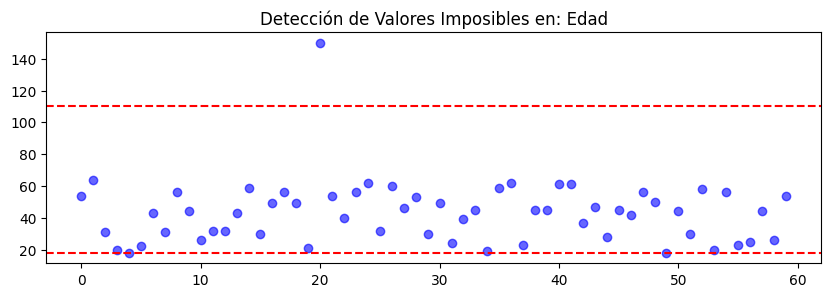

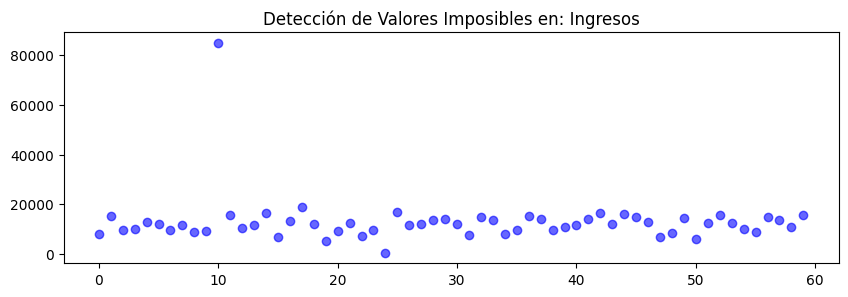

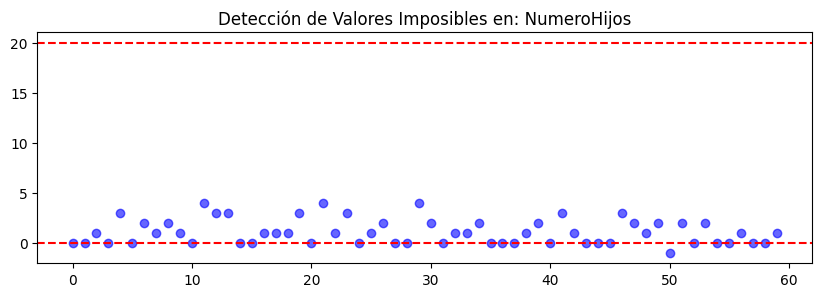

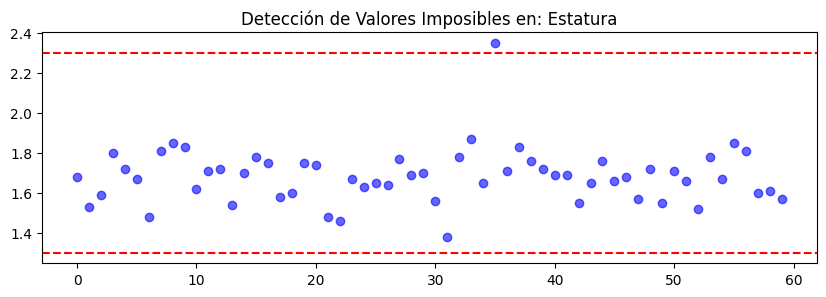

In [ ]:
for v in variables_numericas:
    plt.figure(figsize=(10, 3))

    # 1. Graficamos los puntos para ver cuáles se escapan
    plt.scatter(df.index, df[v], alpha=0.6, color='blue', label='Datos')

    # 2. Si la variable tiene límites lógicos definidos, pintamos líneas rojas de alerta
    if v in umbrales:
        plt.axhline(y=umbrales[v]['max'], color='red', linestyle='--', label='Límite Máximo Lógico')
        plt.axhline(y=umbrales[v]['min'], color='red', linestyle='--', label='Límite Mínimo Lógico')


    plt.title(f'Detección de Valores Imposibles en: {v}')
    plt.show()
    print("")

In [ ]:
df.iloc[48:52]

,Id,Genero,NivelEducacion,Edad,Ingresos,Casado,Satisfaccion,NumeroHijos,Ciudad,FechaRegistro,Estatura,Ocupacion
48,49,Femenino,Bachillerato,50,8403.01,1,5,1,Puebla,2024-12-21,1.72,Estudiante
49,50,Femenino,Secundaria,18,14594.34,0,2,2,Querétaro,2025-01-05,1.55,Empleado
50,51,Masculino,Universidad,44,6013.15,1,2,-1,Toluca,2025-01-20,1.71,Independiente
51,52,Femenino,Bachillerato,30,12416.42,1,3,2,Puebla,2025-02-04,1.66,Estudiante


In [ ]:
#FILTRAMOS A QUIENES SE SALEN DE NUESTRO UMBRAL
df[(df['NumeroHijos'] < umbrales['NumeroHijos']['min']) | (df['NumeroHijos'] > umbrales['NumeroHijos']['max'])]

,Id,Genero,NivelEducacion,Edad,Ingresos,Casado,Satisfaccion,NumeroHijos,Ciudad,FechaRegistro,Estatura,Ocupacion
50,51,Masculino,Universidad,44,6013.15,1,2,-1,Toluca,2025-01-20,1.71,Independiente


In [ ]:
reglas_invalidas = {
#NEGACION ~
    variable: ~df[variable].between(limites['min'], limites['max'])
    for variable, limites in umbrales.items()
}

for variable, mascara in reglas_invalidas.items():
    print()
    print(f'Valores inválidos en {variable}:')
    display(df.loc[mascara, ['Id', variable]])


Valores inválidos en Edad:


,Id,Edad
20,21,150



Valores inválidos en Satisfaccion:


,Id,Satisfaccion
38,39,7



Valores inválidos en NumeroHijos:


,Id,NumeroHijos
50,51,-1



Valores inválidos en Estatura:


,Id,Estatura
35,36,2.35


In [ ]:
#PASAR LOS IMPOSIBLES A NULL
for v, mascaras in reglas_invalidas.items():
    df.loc[mascaras, v] = np.nan

#IMPUTAR LOS NULOS CON LA MEDIANA
for v in ['Edad', 'Satisfaccion', 'NumeroHijos', 'Estatura']:
    df[v] = df[v].fillna(df[v].median())

#RESTAURAR VALORES DESCRETOS
for v in ['Edad', 'Satisfaccion', 'NumeroHijos']:
    df[v] = df[v].round().astype(int)

df[['Edad', 'Satisfaccion', 'NumeroHijos', 'Estatura']].describe()

,Edad,Satisfaccion,NumeroHijos,Estatura
count,60.000000,60.000000,60.000000,60.000000
mean,41.533333,2.933333,1.150000,1.673000
std,13.982394,1.482859,1.218849,0.106123
min,18.000000,1.000000,0.000000,1.380000
25%,30.000000,2.000000,0.000000,1.600000
50%,44.000000,3.000000,1.000000,1.680000
75%,54.000000,4.000000,2.000000,1.750000
max,64.000000,5.000000,4.000000,1.870000


In [ ]:
df.iloc[35]

,35
Id,36
Genero,Masculino
NivelEducacion,Bachillerato
Edad,59
Ingresos,9611.94
Casado,1
Satisfaccion,2
NumeroHijos,0
Ciudad,Toluca
FechaRegistro,2024-06-09


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Id              60 non-null     int64  
 1   Genero          60 non-null     object 
 2   NivelEducacion  60 non-null     object 
 3   Edad            60 non-null     int64  
 4   Ingresos        60 non-null     float64
 5   Casado          60 non-null     int64  
 6   Satisfaccion    60 non-null     int64  
 7   NumeroHijos     60 non-null     int64  
 8   Ciudad          60 non-null     object 
 9   FechaRegistro   60 non-null     object 
 10  Estatura        60 non-null     float64
 11  Ocupacion       60 non-null     object 
dtypes: float64(2), int64(5), object(5)
memory usage: 5.8+ KB


In [ ]:
#CONVERSION DE TIPOS DE DATOS
df['Casado'] = df['Casado'].astype('category')

#CONVERSION A TIPO ORDINAL
orden_satisfaccion = pd.CategoricalDtype(categories=[1, 2, 3, 4, 5], ordered=True)
df['Satisfaccion'] = df['Satisfaccion'].astype(orden_satisfaccion)

In [ ]:
df['FechaRegistro'] = pd.to_datetime(df['FechaRegistro'],
    errors='coerce',
    dayfirst=True,
    format='mixed' #%Y-%m-%d  %d/%m/%Y
)

print(df['FechaRegistro'].dtype)
print('Fechas Invalidas', df['FechaRegistro'].isna().sum())
df[df['FechaRegistro'].isna()]

datetime64[ns]
Fechas Invalidas 1


,Id,Genero,NivelEducacion,Edad,Ingresos,Casado,Satisfaccion,NumeroHijos,Ciudad,FechaRegistro,Estatura,Ocupacion
29,30,Femenino,Secundaria,30,13902.21,0,5,4,Puebla,NaT,1.7,Empleado


In [ ]:
#IMPUTAMOS LAS FECHAS NAN CON LA MEDIANA DE LA FECHA (FECHA DE ENMEDIO)
#fechas_mediana = df['FechaRegistro'].median()
fechas_mediana = df['FechaRegistro'].dropna().sort_values()\
.iloc[len(df['FechaRegistro'].dropna()) // 2]

print(len(df['FechaRegistro'].dropna()) // 2)
print(len(df['FechaRegistro'].dropna()) / 2)
fechas_mediana

29
29.5


Timestamp('2024-04-10 00:00:00')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Id              60 non-null     int64         
 1   Genero          60 non-null     object        
 2   NivelEducacion  60 non-null     object        
 3   Edad            60 non-null     int64         
 4   Ingresos        60 non-null     float64       
 5   Casado          60 non-null     category      
 6   Satisfaccion    60 non-null     category      
 7   NumeroHijos     60 non-null     int64         
 8   Ciudad          60 non-null     object        
 9   FechaRegistro   59 non-null     datetime64[ns]
 10  Estatura        60 non-null     float64       
 11  Ocupacion       60 non-null     object        
dtypes: category(2), datetime64[ns](1), float64(2), int64(3), object(4)
memory usage: 5.3+ KB


In [ ]:
def detectar_outliers_iqr(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    mascara = (serie < limite_inferior) | (serie > limite_superior)
    return mascara, limite_inferior, limite_superior

In [ ]:
for v in variables_numericas:
    mascara, limite_inferior, limite_superior = detectar_outliers_iqr(df[v])
    print(f"{v}: LIMITES [{limite_inferior:.2f}, {limite_superior:.2f}] - outliers: {mascara.sum()}")
    display(df.loc[mascara, ['Id', v]])

Edad: LIMITES [-6.00, 90.00] - outliers: 0


,Id,Edad


Ingresos: LIMITES [2544.41, 21302.50] - outliers: 2


,Id,Ingresos
10,11,85000.0
24,25,500.0


NumeroHijos: LIMITES [-3.00, 5.00] - outliers: 0


,Id,NumeroHijos


Estatura: LIMITES [1.38, 1.97] - outliers: 0


,Id,Estatura


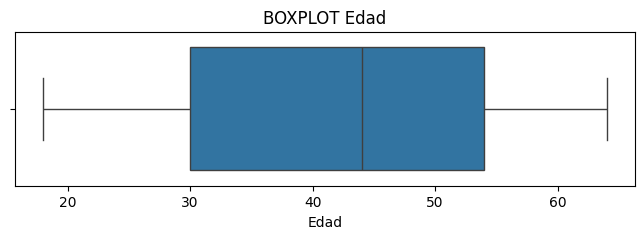

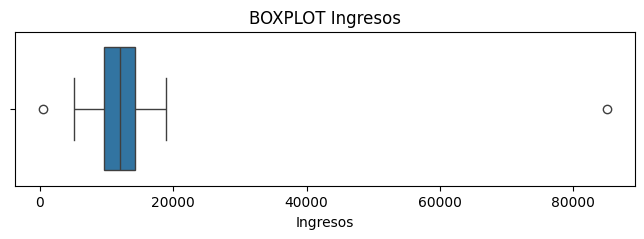

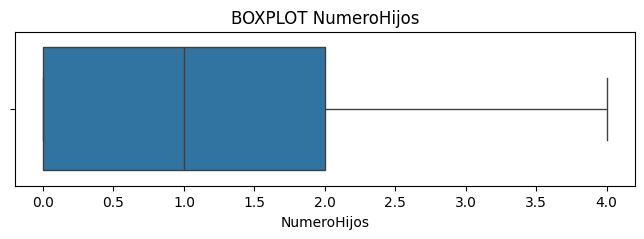

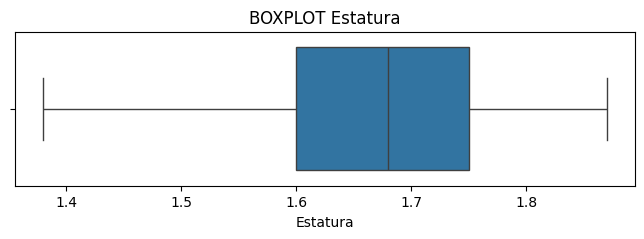

In [ ]:
for v in variables_numericas:
  plt.figure(figsize = (8,2))
  sns.boxplot(x=df[v])
  plt.title(f"BOXPLOT {v}")
  plt.show()

In [ ]:
#DEJAR LOS ATIPICOS DENTRO DEL RANGO INTERCUARTILICO (IQR)
for v in ['Estatura']:
  mascara, limite_inferior, limite_superior = detectar_outliers_iqr(df[v])
  df[v] = df[v].clip(lower=limite_inferior, upper=limite_superior)

# CREACION DE VARIABLES

In [ ]:
#VARIABLES DERIVADAS DE FECHA
df['AnioRegistro'] = df['FechaRegistro'].dt.year
df['MesRegistro'] = df['FechaRegistro'].dt.month
df['DiaRegistro'] = df['FechaRegistro'].dt.day
df[['FechaRegistro', 'AnioRegistro', 'MesRegistro', 'DiaRegistro']].head()


,FechaRegistro,AnioRegistro,MesRegistro,DiaRegistro
0,2023-01-01,2023.0,1.0,1.0
1,2023-01-16,2023.0,1.0,16.0
2,2023-01-31,2023.0,1.0,31.0
3,2023-02-15,2023.0,2.0,15.0
4,2023-03-02,2023.0,3.0,2.0


In [ ]:
df['Estatura_cm'] = df['Estatura'] * 100
df[['Estatura', 'Estatura_cm']].head()

,Estatura,Estatura_cm
0,1.68,168.0
1,1.53,153.0
2,1.59,159.0
3,1.80,180.0
4,1.72,172.0


In [ ]:
#CODIFICACION DE VARIABLES CATEGORICAS
nivel_educacion_orden = {
    'Primaria': 1,
    'Secundaria': 2,
    'Bachillerato': 3,
    'Universidad': 4
}

df['NivelEducacion_orden'] = df['NivelEducacion'].map(nivel_educacion_orden)
df[['NivelEducacion', 'NivelEducacion_orden']].head()

,NivelEducacion,NivelEducacion_orden
0,Bachillerato,3
1,Secundaria,2
2,Primaria,1
3,Universidad,4
4,Universidad,4


In [ ]:
le = LabelEncoder()
df['Genero_le'] = le.fit_transform(df['Genero'])
df[['Genero', 'Genero_le']].head()

,Genero,Genero_le
0,Masculino,1
1,Femenino,0
2,Masculino,1
3,Masculino,1
4,Masculino,1


In [ ]:
le = LabelEncoder()
df['NivelEducacion_label'] = le.fit_transform(df['NivelEducacion'])
df[['NivelEducacion', 'NivelEducacion_orden', 'NivelEducacion_label']].head()

,NivelEducacion,NivelEducacion_orden,NivelEducacion_label
0,Bachillerato,3,0
1,Secundaria,2,2
2,Primaria,1,1
3,Universidad,4,3
4,Universidad,4,3


In [ ]:
columnas_categoricas = ['Ciudad', 'Ocupacion']
df_one_hot = pd.get_dummies(
    df[columnas_categoricas],
    prefix=columnas_categoricas,
    dtype=int,
    drop_first=False
)

print("FORMA DEL df_one_hot", df_one_hot.shape)
df_one_hot.head()

FORMA DEL df_one_hot (60, 11)


,Ciudad_Cdmx,Ciudad_Ciudad de méxico,Ciudad_Cuernavaca,Ciudad_Desconocida,Ciudad_Puebla,Ciudad_Querétaro,Ciudad_Toluca,Ocupacion_Desempleado,Ocupacion_Empleado,Ocupacion_Estudiante,Ocupacion_Independiente
0,0,0,1,0,0,0,0,0,1,0,0
1,0,0,0,0,0,1,0,0,0,0,1
2,0,0,1,0,0,0,0,0,0,1,0
3,0,0,0,0,1,0,0,0,0,1,0
4,0,0,0,0,1,0,0,0,1,0,0


In [ ]:
df_one_hot_drop = pd.get_dummies(
    df[columnas_categoricas],
    prefix=columnas_categoricas,
    dtype=int,
    drop_first=True
)

print("FORMA DEL df_one_hot", df_one_hot_drop.shape)
df_one_hot_drop.head(10)

FORMA DEL df_one_hot (60, 9)


,Ciudad_Ciudad de méxico,Ciudad_Cuernavaca,Ciudad_Desconocida,Ciudad_Puebla,Ciudad_Querétaro,Ciudad_Toluca,Ocupacion_Empleado,Ocupacion_Estudiante,Ocupacion_Independiente
0,0,1,0,0,0,0,1,0,0
1,0,0,0,0,1,0,0,0,1
2,0,1,0,0,0,0,0,1,0
3,0,0,0,1,0,0,0,1,0
4,0,0,0,1,0,0,1,0,0
5,0,0,0,0,1,0,0,0,0
6,0,1,0,0,0,0,1,0,0
7,1,0,0,0,0,0,1,0,0
8,0,0,0,0,1,0,0,1,0
9,0,0,0,1,0,0,0,0,0


In [ ]:
# Unir el df con las variables dummies
df_codificado = pd.concat([df, df_one_hot], axis=1)
print("FORMA DEL df_one_hot", df_codificado.shape)
df_codificado.head()

FORMA DEL df_one_hot (60, 30)


,Id,Genero,NivelEducacion,Edad,Ingresos,Casado,Satisfaccion,NumeroHijos,Ciudad,FechaRegistro,Estatura,Ocupacion,AnioRegistro,MesRegistro,DiaRegistro,Estatura_cm,NivelEducacion_orden,Genero_le,NivelEducacion_label,Ciudad_Cdmx,Ciudad_Ciudad de méxico,Ciudad_Cuernavaca,Ciudad_Desconocida,Ciudad_Puebla,Ciudad_Querétaro,Ciudad_Toluca,Ocupacion_Desempleado,Ocupacion_Empleado,Ocupacion_Estudiante,Ocupacion_Independiente
0,1,Masculino,Bachillerato,54,8163.07,0,3,0,Cuernavaca,2023-01-01,1.68,Empleado,2023.0,1.0,1.0,168.0,3,1,0,0,0,1,0,0,0,0,0,1,0,0
1,2,Femenino,Secundaria,64,15202.10,1,2,0,Querétaro,2023-01-16,1.53,Independiente,2023.0,1.0,16.0,153.0,2,0,2,0,0,0,0,0,1,0,0,0,0,1
2,3,Masculino,Primaria,31,9668.79,1,5,1,Cuernavaca,2023-01-31,1.59,Estudiante,2023.0,1.0,31.0,159.0,1,1,1,0,0,1,0,0,0,0,0,0,1,0
3,4,Masculino,Universidad,20,10201.74,0,1,0,Puebla,2023-02-15,1.80,Estudiante,2023.0,2.0,15.0,180.0,4,1,3,0,0,0,0,1,0,0,0,0,1,0
4,5,Masculino,Universidad,18,13054.63,0,4,3,Puebla,2023-03-02,1.72,Empleado,2023.0,3.0,2.0,172.0,4,1,3,0,0,0,0,1,0,0,0,1,0,0


## DISCRETIZACION DE VARIABLES

In [ ]:
# DISCRETIZACION DE VARIBALES
bins_edad = [17, 29, 44, 59, 100]
etiquetas_edad = ['Adulto Joven', 'Adulto', 'Adulto Mayor', 'Anciano']

In [ ]:
df['CategoriaEdad'] = pd.cut(
    df['Edad'],
    bins=bins_edad,
    labels=etiquetas_edad,
    include_lowest=True
)

df[['Edad', 'CategoriaEdad']].head(10)

,Edad,CategoriaEdad
0,54,Adulto Mayor
1,64,Anciano
2,31,Adulto
3,20,Adulto Joven
4,18,Adulto Joven
5,22,Adulto Joven
6,43,Adulto
7,31,Adulto
8,56,Adulto Mayor
9,44,Adulto


In [ ]:
# DISCRETIZACION POR CUANTILES
df['CuartilIngresos'] = pd.qcut(
    df['Ingresos'],
    q=4,
    labels=['Q1', 'Q2', 'Q3', 'Q4']
)

print(df['CuartilIngresos'].value_counts().sort_index())
df[['Ingresos', 'CuartilIngresos']].head(10)

CuartilIngresos
Q1    15
Q2    17
Q3    13
Q4    15
Name: count, dtype: int64


,Ingresos,CuartilIngresos
0,8163.07,Q1
1,15202.10,Q4
2,9668.79,Q2
3,10201.74,Q2
4,13054.63,Q3
5,11969.72,Q2
6,9680.42,Q2
7,11487.35,Q2
8,9038.94,Q1
9,9121.29,Q1


In [ ]:
df[['Ingresos', 'CuartilIngresos']][df['Ingresos'] > 20000]

,Ingresos,CuartilIngresos
10,85000.0,Q4


## ESTANDARIZACION Y NORMALIZACION

In [ ]:
#ESTANDARIZACION MEDIA 0 Y DESVIACION ESTANDAR 1 (z_score)
#NORMALIZACION INTERVALO ENTRE 0 Y 1
variables_escalar = ['Edad', 'Ingresos', 'NumeroHijos', 'Estatura']
standar_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

#df[variables_escalar] = standar_scaler.fit_transform(df[variables_escalar])
#df[variables_escalar] = minmax_scaler.fit_transform(df[variables_escalar])


df_standar = pd.DataFrame(
    standar_scaler.fit_transform(df[variables_escalar]),
    columns= [f'z_{c}' for c in variables_escalar],
    index = df.index
)

df_minmax = pd.DataFrame(
    minmax_scaler.fit_transform(df[variables_escalar]),
    columns= [f'minmax_{c}' for c in variables_escalar],
    index = df.index
)

df_escalado = pd.concat([df[variables_escalar], df_standar, df_minmax], axis=1)
df_escalado.head()

,Edad,Ingresos,NumeroHijos,Estatura,z_Edad,z_Ingresos,z_NumeroHijos,z_Estatura,minmax_Edad,minmax_Ingresos,minmax_NumeroHijos,minmax_Estatura
0,54,8163.07,0,1.68,0.899122,-0.477585,-0.951475,0.066518,0.782609,0.090687,0.00,0.612245
1,64,15202.10,0,1.53,1.620342,0.229852,-0.951475,-1.358868,1.000000,0.173989,0.00,0.306122
2,31,9668.79,1,1.59,-0.759686,-0.326257,-0.124105,-0.788714,0.282609,0.108506,0.25,0.428571
3,20,10201.74,0,1.80,-1.553028,-0.272695,-0.951475,1.206827,0.043478,0.114813,0.00,0.857143
4,18,13054.63,3,1.72,-1.697272,0.014027,1.530634,0.446621,0.000000,0.148576,0.75,0.693878


In [ ]:
df_escalado[df_escalado['Ingresos'] > 20000]

,Edad,Ingresos,NumeroHijos,Estatura,z_Edad,z_Ingresos,z_NumeroHijos,z_Estatura,minmax_Edad,minmax_Ingresos,minmax_NumeroHijos,minmax_Estatura
10,26,85000.0,0,1.62,-1.120296,7.244682,-0.951475,-0.503636,0.173913,1.0,0.0,0.489796


In [ ]:
df_escalado.describe().T

,count,mean,std,min,25%,50%,75%,max
Edad,60.0,4.153333e+01,13.982394,18.000000,30.000000,44.000000,54.000000,64.000000
Ingresos,60.0,1.291506e+04,10034.016738,500.000000,9578.695000,11969.720000,14268.217500,85000.000000
NumeroHijos,60.0,1.150000e+00,1.218849,0.000000,0.000000,1.000000,2.000000,4.000000
Estatura,60.0,1.673000e+00,0.106123,1.380000,1.600000,1.680000,1.750000,1.870000
z_Edad,60.0,1.350771e-16,1.008439,-1.697272,-0.831808,0.177901,0.899122,1.620342
z_Ingresos,60.0,-1.813364e-16,1.008439,-1.247739,-0.335312,-0.095009,0.135995,7.244682
z_NumeroHijos,60.0,8.442321e-17,1.008439,-0.951475,-0.951475,-0.124105,0.703264,2.358004
z_Estatura,60.0,3.795112e-15,1.008439,-2.784254,-0.693688,0.066518,0.731698,1.872007
minmax_Edad,60.0,5.115942e-01,0.303965,0.000000,0.260870,0.565217,0.782609,1.000000
minmax_Ingresos,60.0,1.469238e-01,0.118746,0.000000,0.107440,0.135736,0.162937,1.000000


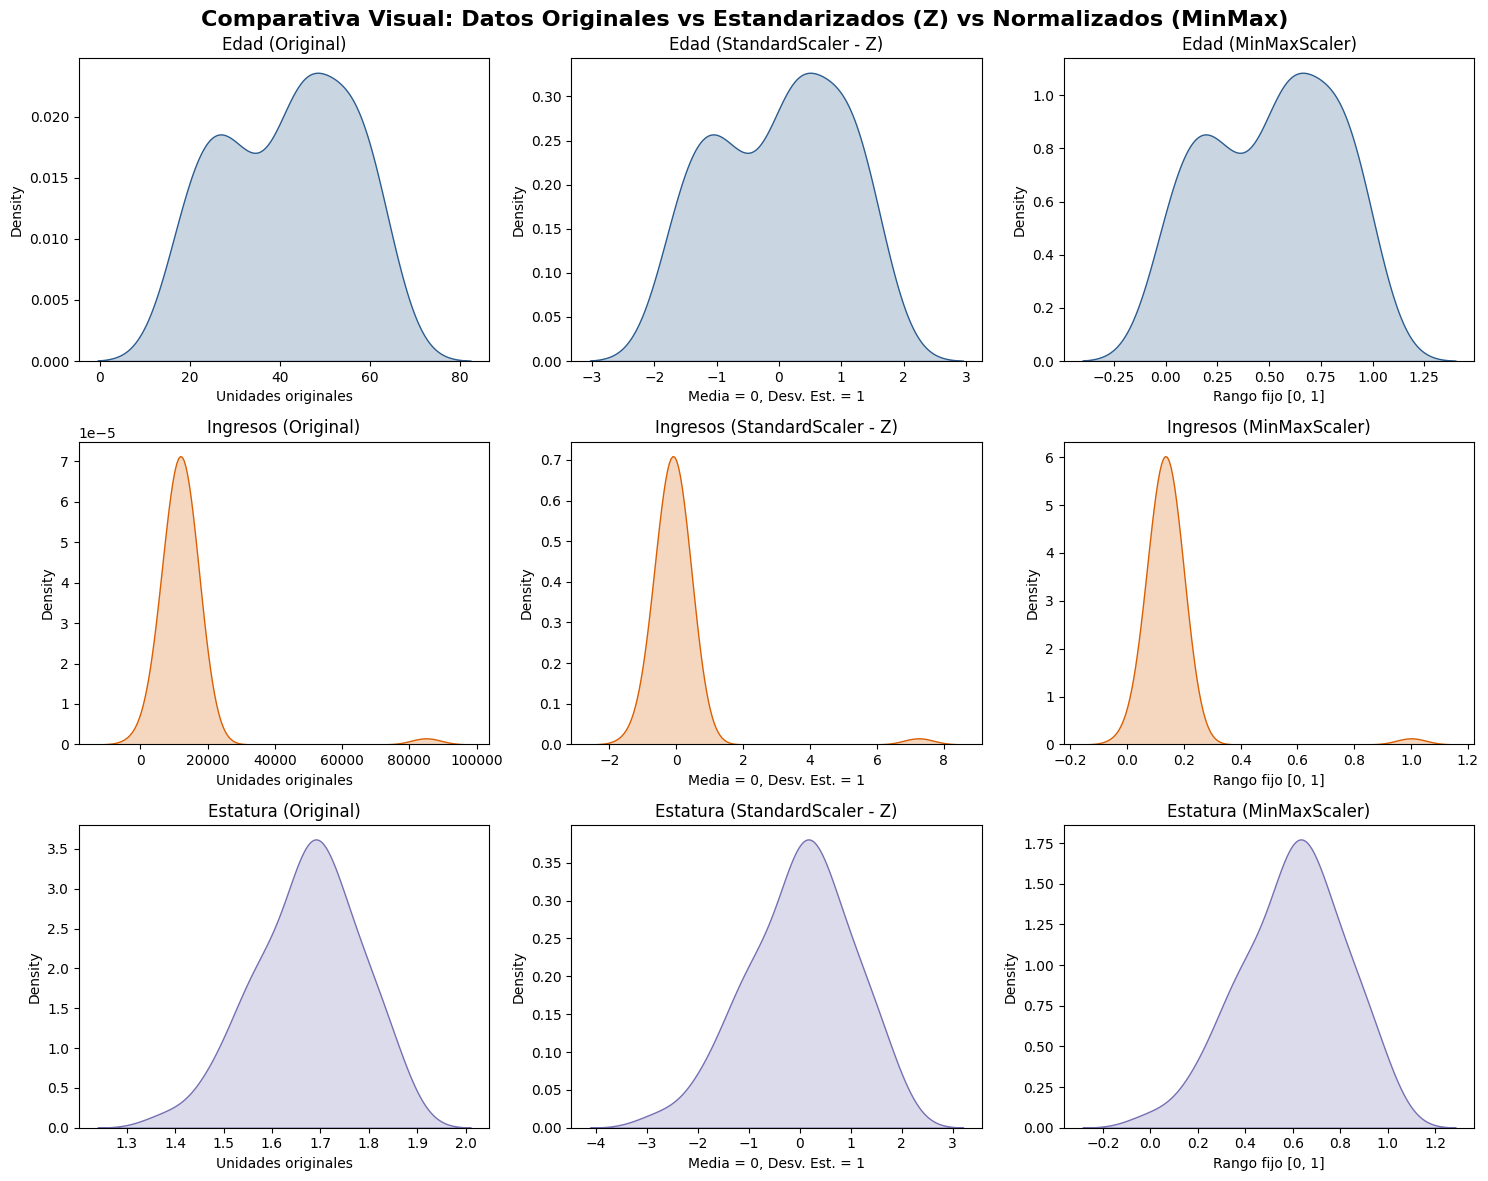

In [ ]:
  # Configurar la cuadrícula de gráficos (3 filas para las variables comunes x 3 columnas de estados)
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
fig.suptitle('Comparativa Visual: Datos Originales vs Estandarizados (Z) vs Normalizados (MinMax)', fontsize=16, fontweight='bold')


variables_escalar_g = ['Edad', 'Ingresos', 'Estatura']
# Lista de variables base que tienen ambas transformaciones
colores = ['#2b5c8f', '#d95f02', '#7570b3']

for i, var in enumerate(variables_escalar_g):
    # Columna 1: Originales
    sns.kdeplot(df_escalado[var], ax=axes[i, 0], color=colores[i], fill=True)
    axes[i, 0].set_title(f'{var} (Original)')
    axes[i, 0].set_xlabel('Unidades originales')

    # Columna 2: StandardScaler (Columna con sufijo _Z)
    col_z = f'z_{var}'
    if col_z in df_escalado.columns:
        sns.kdeplot(df_escalado[col_z], ax=axes[i, 1], color=colores[i], fill=True)
        axes[i, 1].set_title(f'{var} (StandardScaler - Z)')
        axes[i, 1].set_xlabel('Media = 0, Desv. Est. = 1')

    # Columna 3: MinMaxScaler (Columna con sufijo minmax_)
    col_mm = f'minmax_{var}'
    if col_mm in df_escalado:
        sns.kdeplot(df_escalado[col_mm], ax=axes[i, 2], color=colores[i], fill=True)
        axes[i, 2].set_title(f'{var} (MinMaxScaler)')
        axes[i, 2].set_xlabel('Rango fijo [0, 1]')

plt.tight_layout()
plt.show()